In [3]:
# Importer les packages
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

In [1]:
# Supprimer les warning
import warnings
warnings.filterwarnings("ignore")

### <font color = 'teal'>Importer et Lire les données<font>

In [4]:
# importer les données
df = pd.read_csv('data/Bank_Data.csv')

In [5]:
#Afficher les données
df.head()

,age,job,marital,education,housing,loan,contact,month,day_of_week,duration,campaign,pdays,previous,poutcome,y
0,28,management,single,university.degree,yes,no,cellular,jun,thu,339,3,6,2,success,yes
1,55,retired,married,basic.4y,yes,no,cellular,aug,fri,137,1,3,1,success,yes
2,36,admin.,married,university.degree,no,no,cellular,jun,mon,174,1,3,1,success,yes
3,55,management,married,university.degree,no,no,cellular,aug,mon,372,3,999,0,nonexistent,yes
4,35,services,married,high.school,no,no,cellular,apr,thu,1034,2,999,0,nonexistent,yes


#### <font color = "bisque">Concernant les données<font>
Les données sont liées aux campagnes de marketing direct (appels téléphoniques) d'une institution bancaire portugaise. L'objectif de la classification est de prédire si le client souscrira un dépôt à terme (term deposit) (variable y). Les données sont issues de [UCI repository](https://archive.ics.uci.edu/dataset/222/bank+marketing)


#### Description des variables du jeu de données "Bank Marketing"

Ce jeu de données contient des informations issues de campagnes de marketing téléphonique réalisées par une banque portugaise. L'objectif est de prédire si un client souscrira à un dépôt à terme (`y`).

| Variable           | Type          | Description |
|--------------------|---------------|-------------|
| `age`              | Numérique     | Âge du client (en années). |
| `job`              | Catégorielle  | Profession du client (ex. : 'admin.', 'technician', 'services', etc.). |
| `marital`          | Catégorielle  | Statut marital du client (ex. : 'married', 'single', 'divorced'). |
| `education`        | Catégorielle  | Niveau d'éducation du client (ex. : 'basic.4y', 'high.school', 'university.degree'). |
| `default`          | Binaire       | Le client a-t-il un crédit en défaut ? ('yes', 'no'). |
| `housing`          | Binaire       | Le client a-t-il un prêt immobilier ? ('yes', 'no'). |
| `loan`             | Binaire       | Le client a-t-il un prêt personnel ? ('yes', 'no'). |
| `contact`          | Catégorielle  | Type de contact utilisé pour la communication ('cellular', 'telephone'). |
| `month`            | Catégorielle  | Mois du dernier contact client (ex. : 'may', 'aug', 'nov'). |
| `day_of_week`      | Catégorielle  | Jour de la semaine du dernier contact (ex. : 'mon', 'tue', ...). |
| `duration`         | Numérique     | Durée du dernier contact (en secondes). **Important : cette variable est très corrélée à la cible `y`**. |
| `campaign`         | Numérique     | Nombre de contacts effectués durant cette campagne. |
| `pdays`            | Numérique     | Nombre de jours depuis le dernier contact d'une campagne précédente (999 signifie "jamais contacté auparavant"). |
| `previous`         | Numérique     | Nombre de contacts effectués avant cette campagne. |
| `poutcome`         | Catégorielle  | Résultat de la campagne marketing précédente ('success', 'failure', 'nonexistent'). |
| `y`                | Cible (binaire) | Le client a-t-il souscrit à un dépôt à terme ? ('yes', 'no'). |


In [6]:
# dimension des données
df.shape

(11640, 15)

In [7]:
# infos des données
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 11640 entries, 0 to 11639
Data columns (total 15 columns):
 #   Column       Non-Null Count  Dtype
---  ------       --------------  -----
 0   age          11640 non-null  int64
 1   job          11640 non-null  str  
 2   marital      11640 non-null  str  
 3   education    11640 non-null  str  
 4   housing      11640 non-null  str  
 5   loan         11640 non-null  str  
 6   contact      11640 non-null  str  
 7   month        11640 non-null  str  
 8   day_of_week  11640 non-null  str  
 9   duration     11640 non-null  int64
 10  campaign     11640 non-null  int64
 11  pdays        11640 non-null  int64
 12  previous     11640 non-null  int64
 13  poutcome     11640 non-null  str  
 14  y            11640 non-null  str  
dtypes: int64(5), str(10)
memory usage: 2.0 MB


### <font color = 'gold'>Exploration des données<font>

##### <font color = 'bisque'>Séléction des variables

In [8]:
# sélection des variables catégorielles en utilisant select_dtypes
cat_data = df.select_dtypes(include = 'object')
cat_data.head()

,job,marital,education,housing,loan,contact,month,day_of_week,poutcome,y
0,management,single,university.degree,yes,no,cellular,jun,thu,success,yes
1,retired,married,basic.4y,yes,no,cellular,aug,fri,success,yes
2,admin.,married,university.degree,no,no,cellular,jun,mon,success,yes
3,management,married,university.degree,no,no,cellular,aug,mon,nonexistent,yes
4,services,married,high.school,no,no,cellular,apr,thu,nonexistent,yes


In [9]:
# sélection des variables quantitatives en utilisant select_dtypes
num_data = df.select_dtypes(include = 'number')
num_data.head()

,age,duration,campaign,pdays,previous
0,28,339,3,6,2
1,55,137,1,3,1
2,36,174,1,3,1
3,55,372,3,999,0
4,35,1034,2,999,0


##### <font color = 'bisque'> Exploration des variables catégorielles

In [10]:
# décrire les variables catégorielles
cat_data.describe().T

,count,unique,top,freq
job,11640,12,admin.,3103
marital,11640,4,married,6853
education,11640,8,university.degree,3703
housing,11640,3,yes,6146
loan,11640,3,no,9650
contact,11640,2,cellular,8180
month,11640,10,may,3284
day_of_week,11640,5,thu,2518
poutcome,11640,3,nonexistent,9346
y,11640,2,no,7000


In [11]:
# fonction de countplot
def countplot_func(col):
  val = df[col].value_counts()
  plt.figure(figsize=(25,3))
  sns.barplot(x=val.index, y=val.values, hue = val.index, palette = sns.hls_palette())
  plt.show()

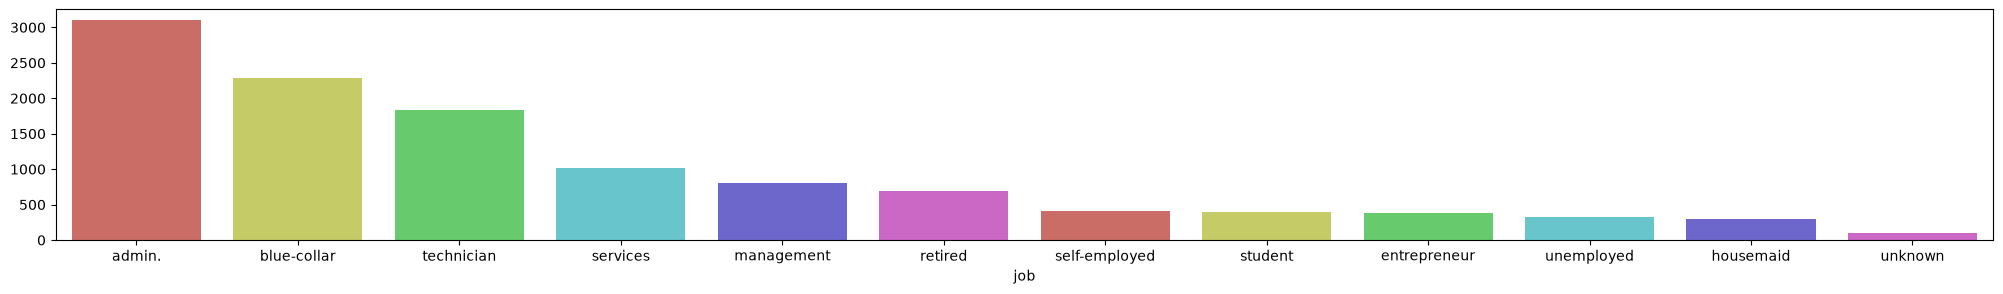

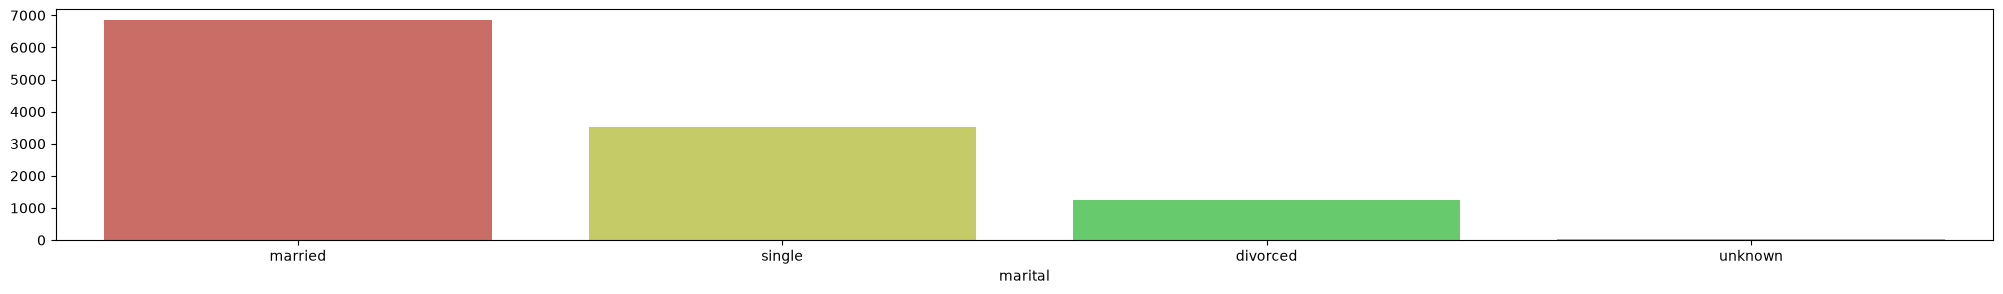

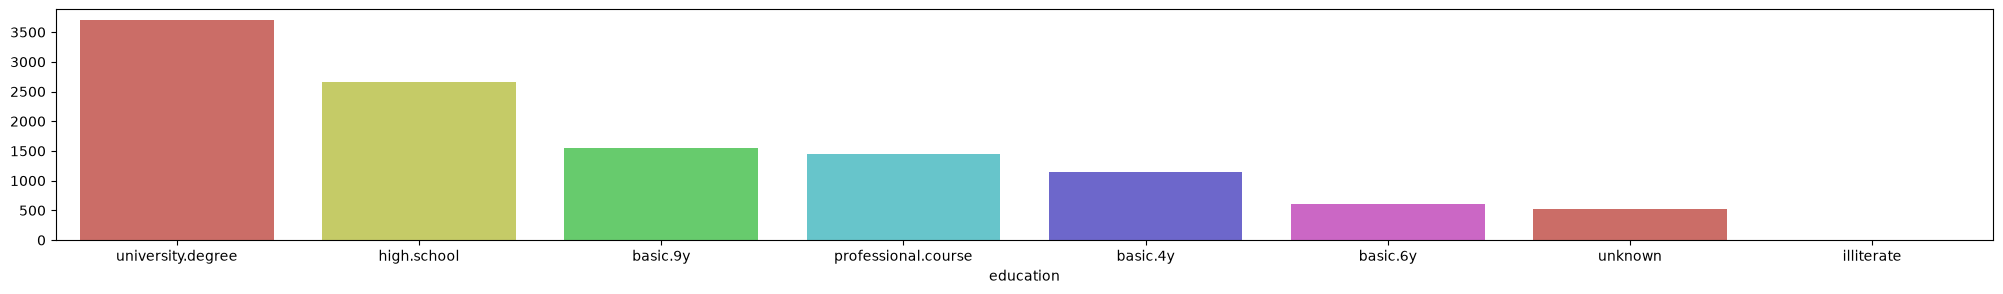

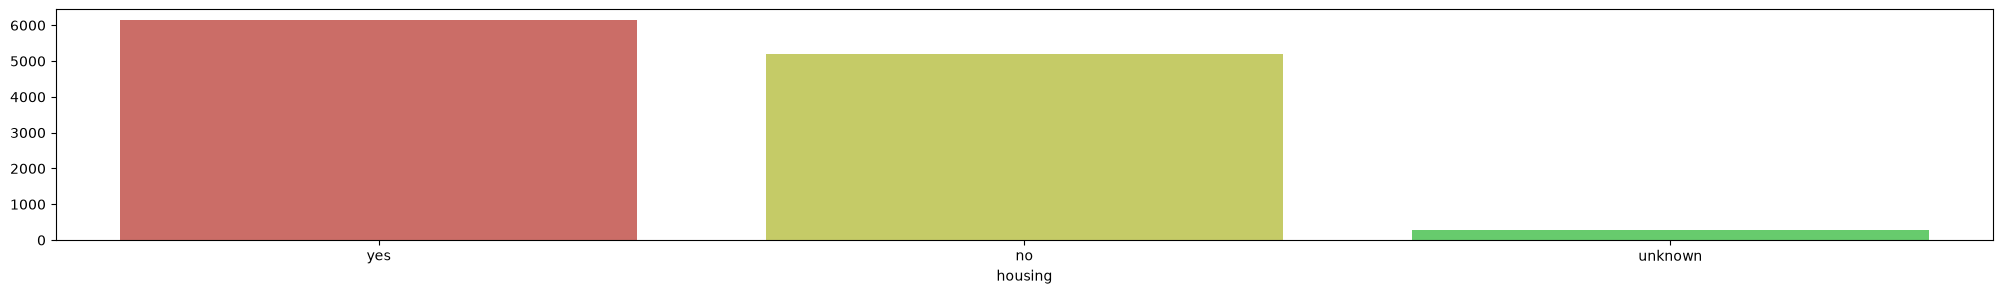

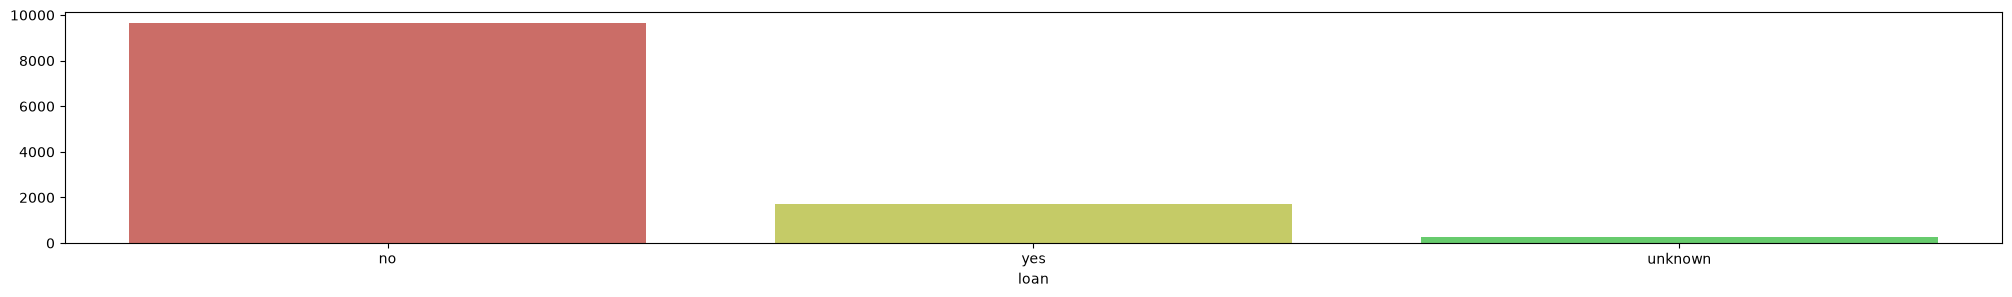

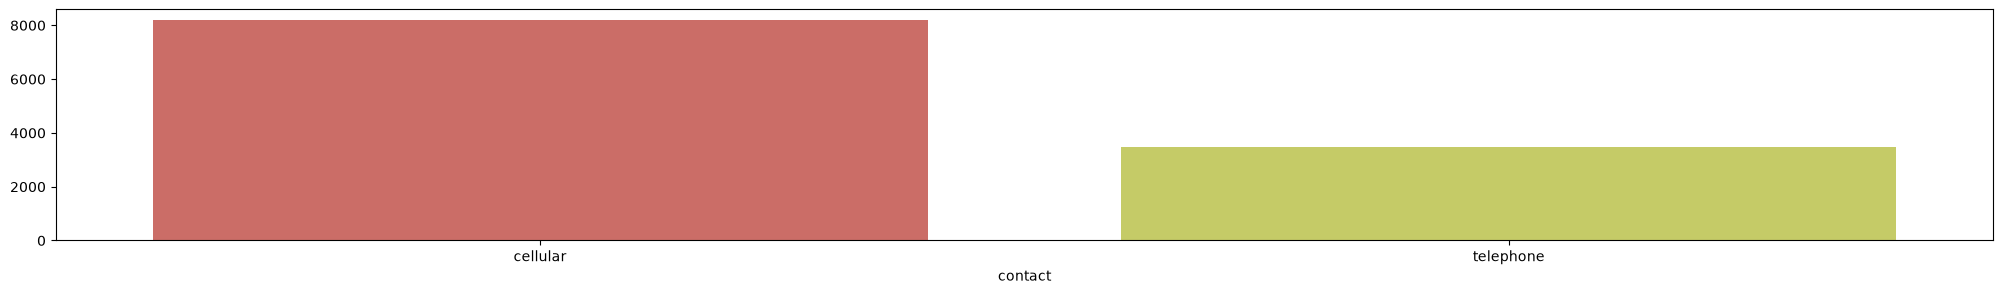

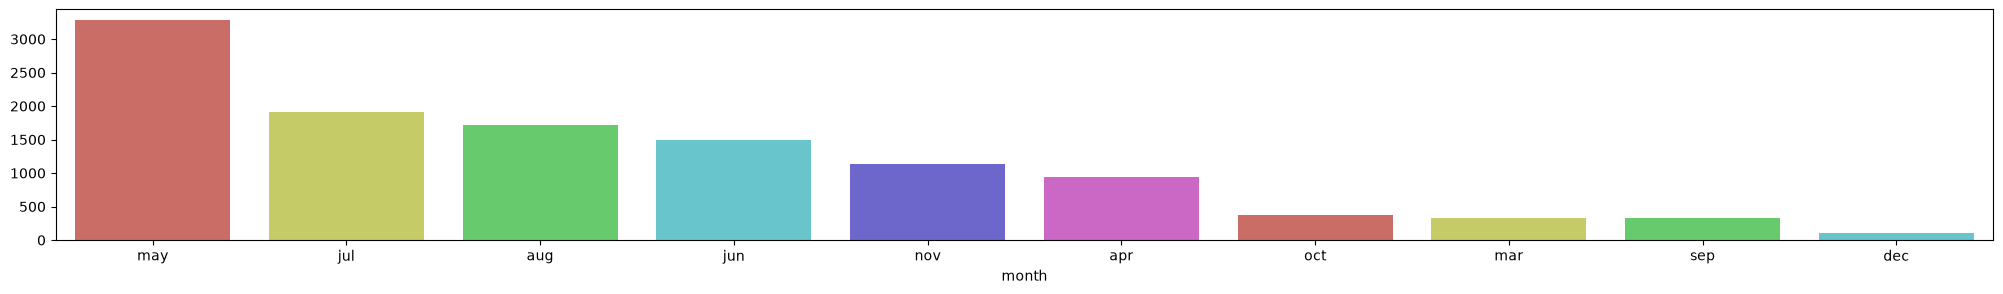

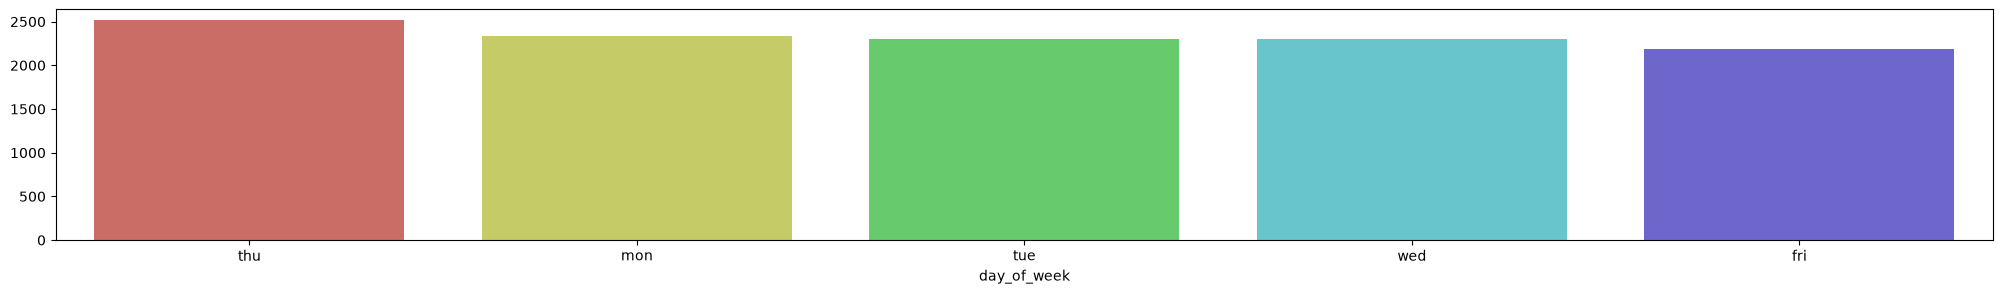

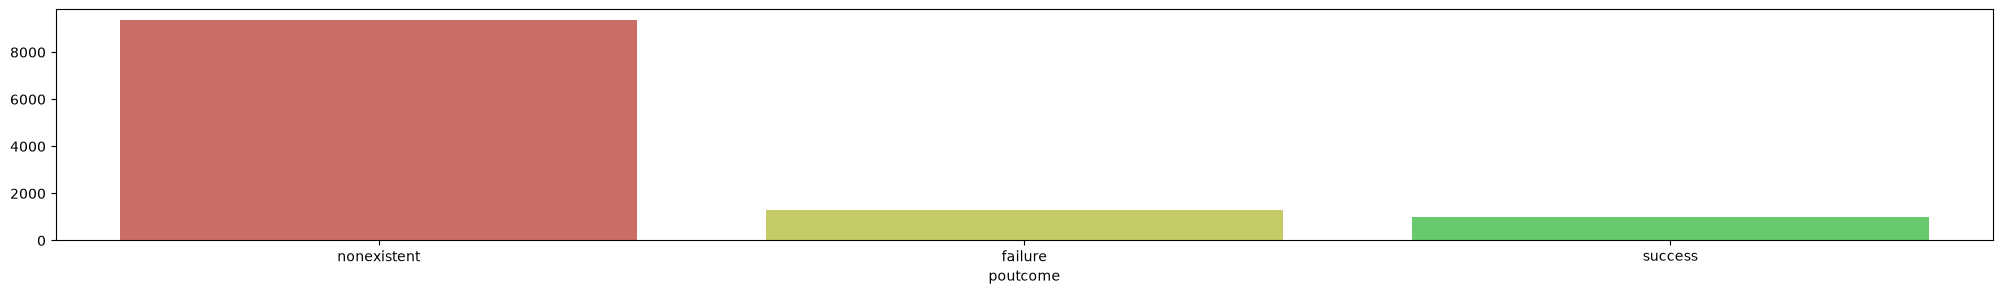

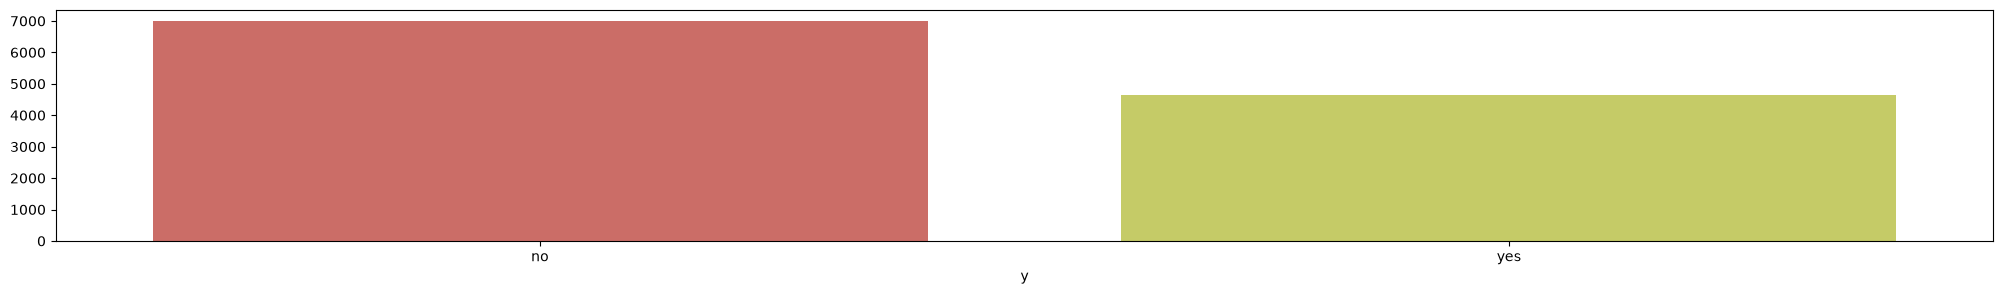

In [11]:
# Countplots de toutes les variables
for col in cat_data.columns:
  countplot_func(col)

##### <font color = 'bisque'> Exploration des variables quantitatives

In [12]:
# décrire les variables quantitatives
num_data.describe().T

,count,mean,std,min,25%,50%,75%,max
age,11640.0,40.325515,11.639351,17.0,32.0,38.0,48.0,98.0
duration,11640.0,354.709021,341.481865,1.0,131.0,238.0,466.0,4199.0
campaign,11640.0,2.378608,2.377445,1.0,1.0,2.0,3.0,39.0
pdays,11640.0,907.797766,286.811601,0.0,999.0,999.0,999.0,999.0
previous,11640.0,0.278093,0.656532,0.0,0.0,0.0,0.0,6.0


In [13]:
num_data.pdays.unique()

array([  6,   3, 999,   0,   5,  11,  14,   9,  15,   4,  26,   7,  19,
         2,  10,  13,  16,  12,   8,  18,   1,  21,  22,  17,  25,  27])

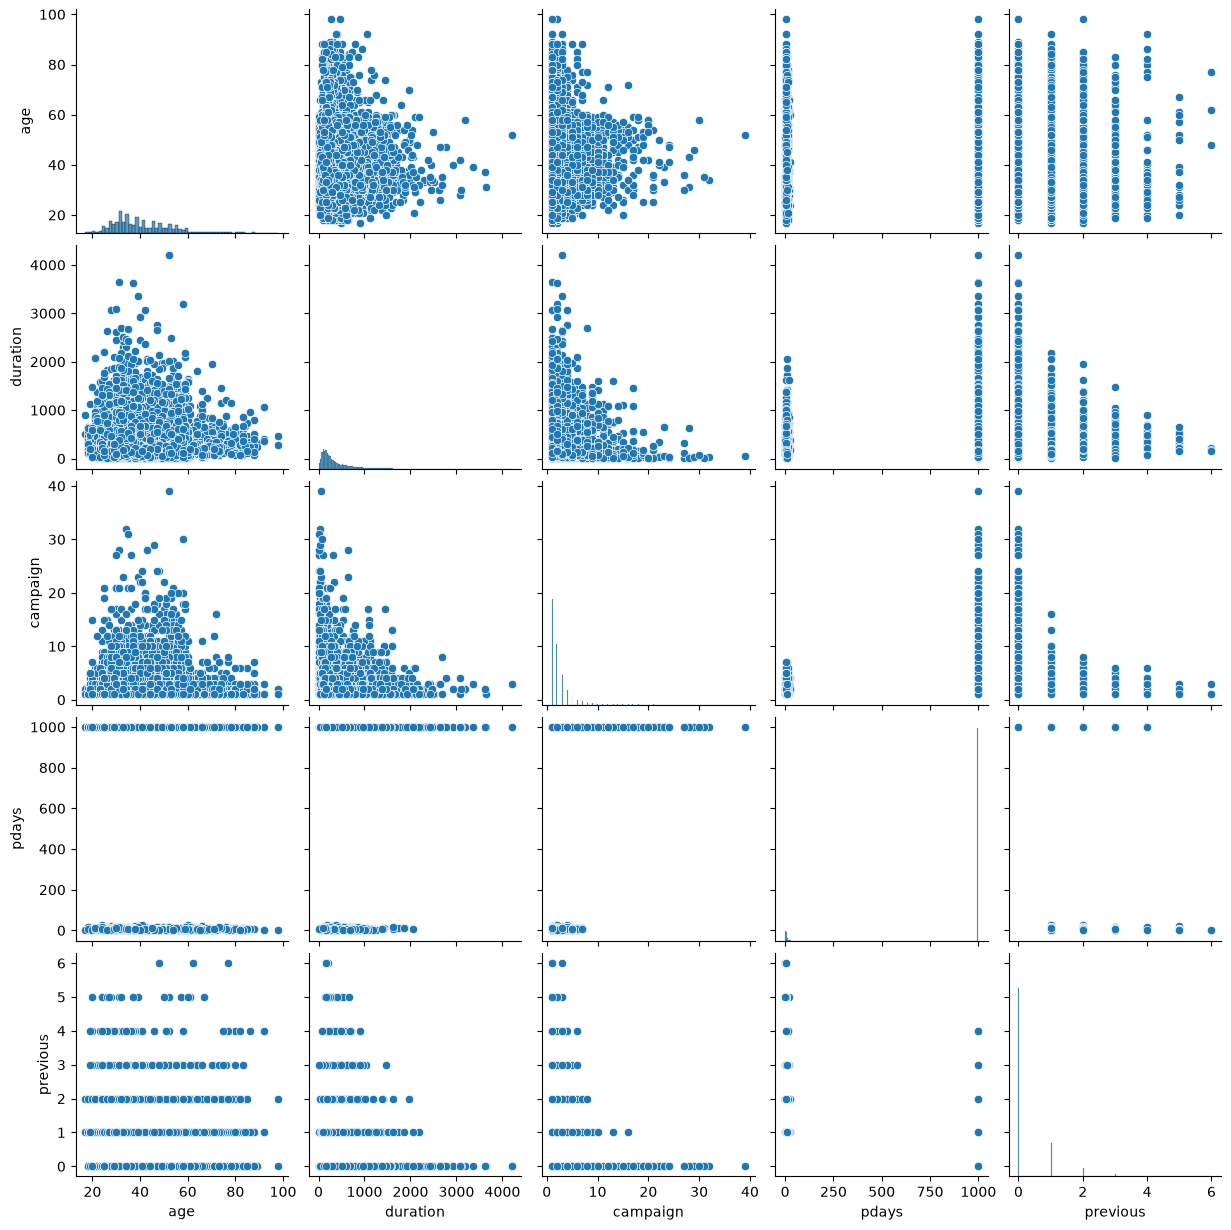

In [14]:
# pairplot
sns.pairplot(num_data)
plt.show()

In [15]:
# fonction boxplots
def boxplot_func(col):
  plt.figure(figsize=(25,3))
  sns.boxplot(x=df[col])
  plt.show()

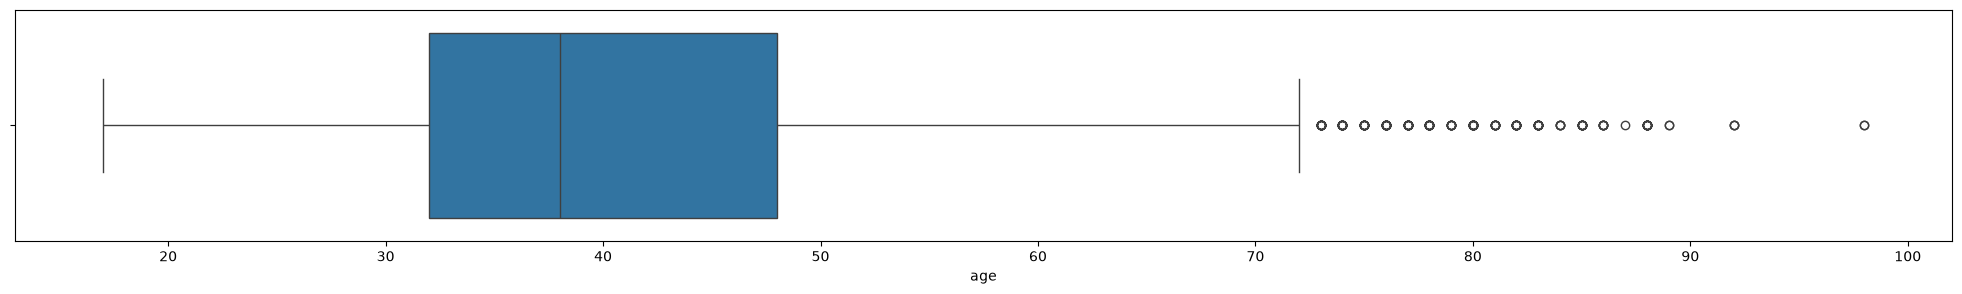

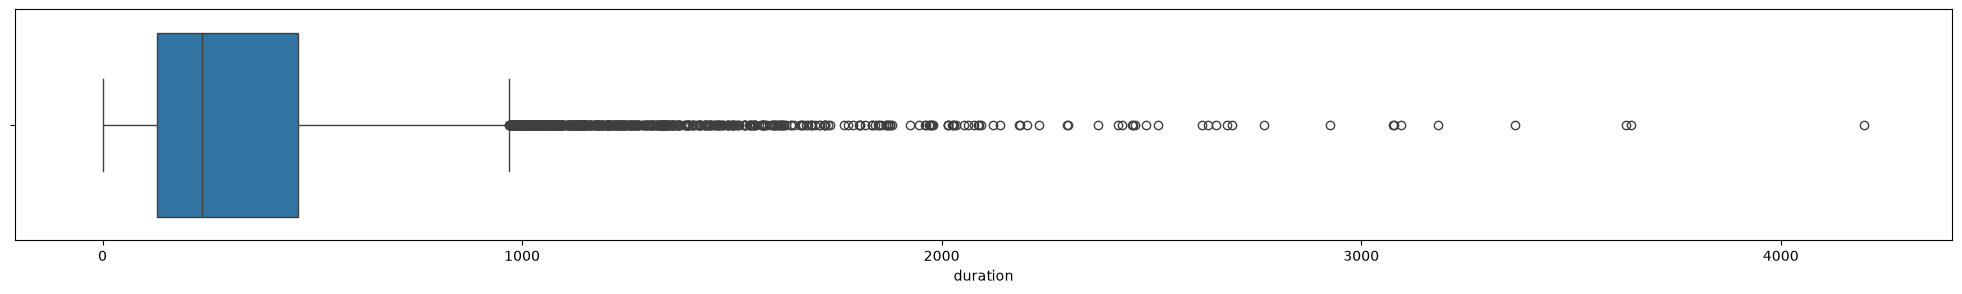

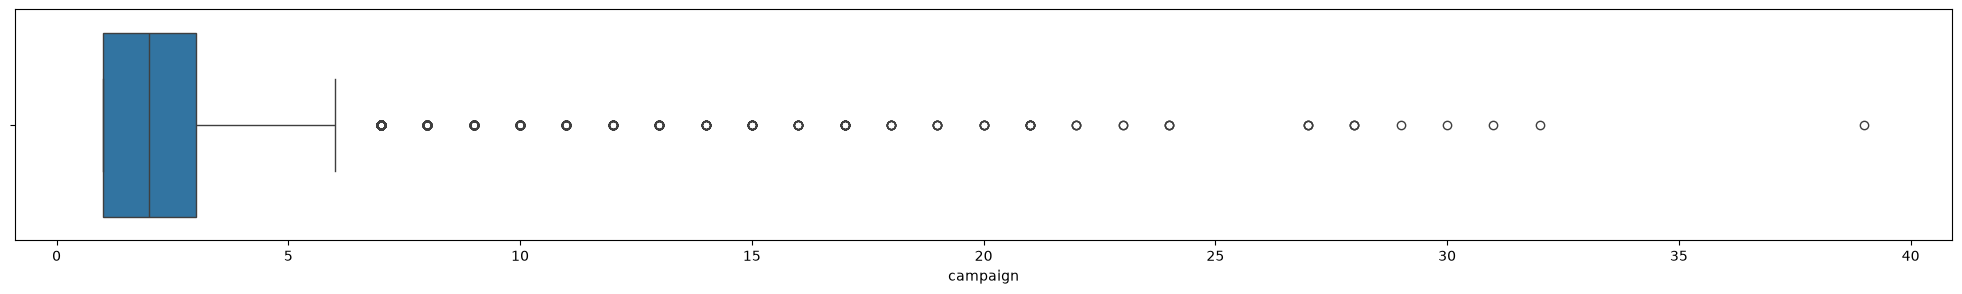

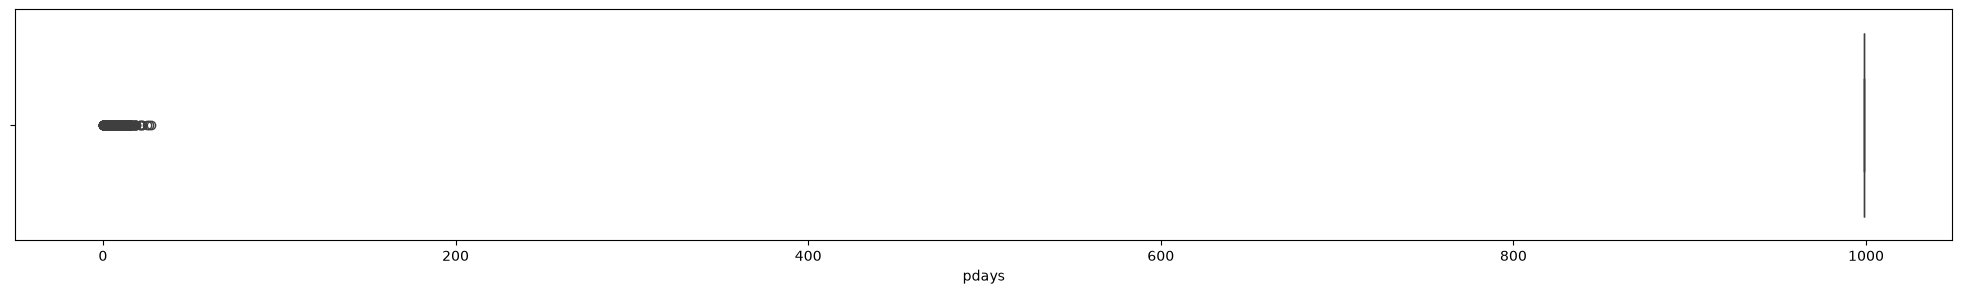

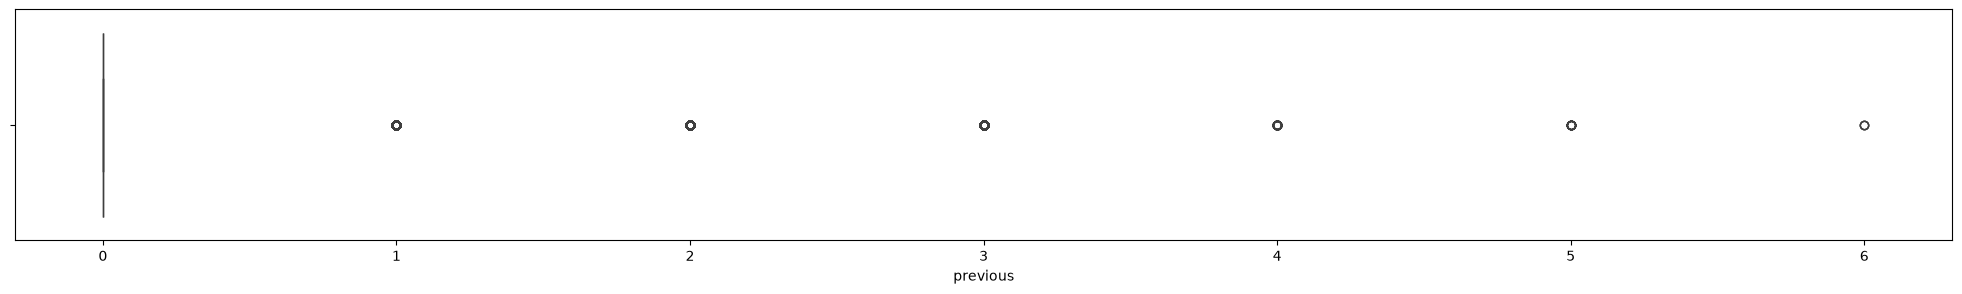

In [16]:
# boxplots des toutes les variables quantitatives
for col in num_data.columns:
  boxplot_func(col)

### <font color = 'gold'>Preparation des données<font>



##### <font color = 'bisque'> Preparation des variables catégorielles

In [22]:
import joblib as jb
from outils.utils import (
    encode_categorical_variables,
    save_categorical_uniques
)
# Enregistrer les valeurs uniques des variables catégorielles dans un objet joblib


In [23]:
# faire un dumping de la liste des valeurs uniques
uniques = save_categorical_uniques(
    df,
    cat_data,
    "metadata/uniques.joblib"
)

In [35]:
# Encoder les variables catégorielles
from outils.utils import encode_categorical_variables 
df, encoders = encode_categorical_variables(
    df,
    "metadata/encoders.joblib"
)

In [ ]:
df.head()

,age,job,marital,education,housing,loan,contact,month,day_of_week,duration,campaign,pdays,previous,poutcome,y
0,28,4,2,6,2,0,0,4,2,339,3,6,2,2,1
1,55,5,1,0,2,0,0,1,0,137,1,3,1,2,1
2,36,0,1,6,0,0,0,4,1,174,1,3,1,2,1
3,55,4,1,6,0,0,0,1,1,372,3,999,0,1,1
4,35,7,1,3,0,0,0,0,2,1034,2,999,0,1,1


##### <font color = 'bisque'> Preparation des quantitatives

In [27]:
# Fonction d'imputation des valeurs aberrantes par la médiane
def imputation_func(df, col):
  Q1 = df[col].quantile(0.25)
  Q3 = df[col].quantile(0.75)
  IQR = Q3 - Q1
  df[col] = np.where((df[col] < (Q1 - 1.5 * IQR)) | (df[col] > (Q3 + 1.5 * IQR)), df[col].median(),df[col])

In [28]:
# imputer les valeurs aberrantes sur les variables  (age, duration, campaign )
for col in num_data.columns[:3]:
  imputation_func(df,col)

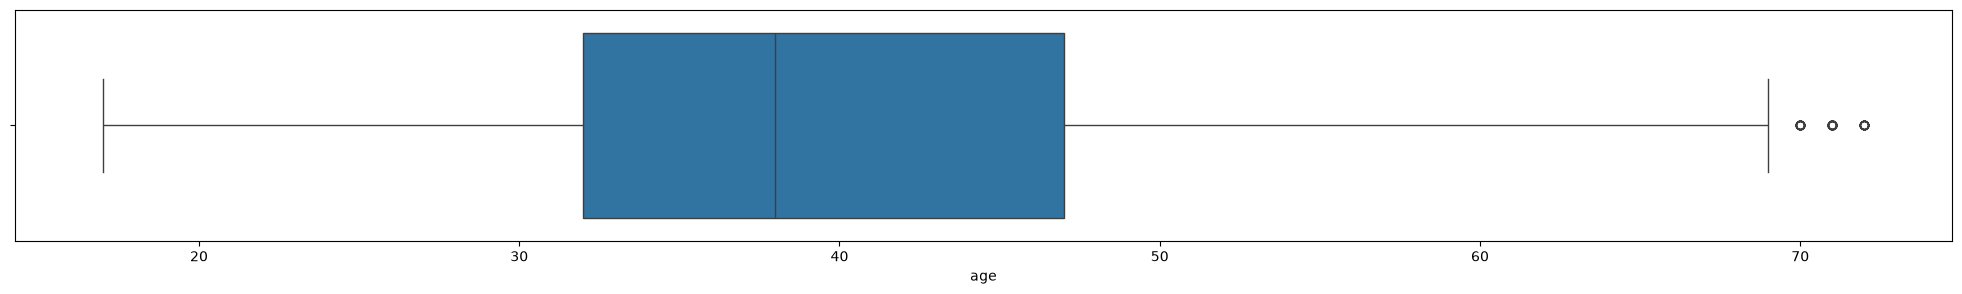

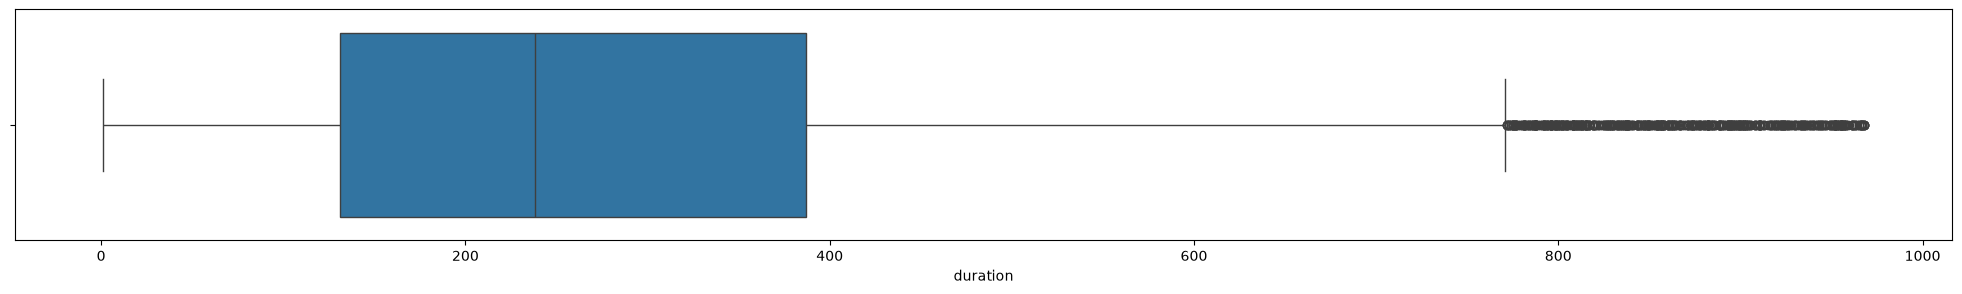

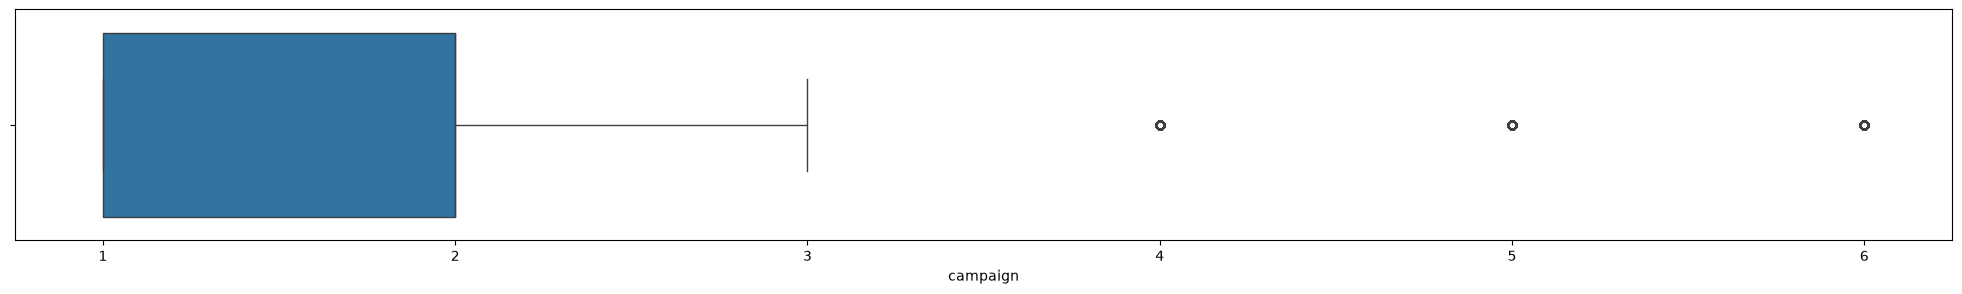

In [29]:
# réafficher les boxplots
for col in num_data.columns[:3]:
  boxplot_func(col)

##### <font color = 'bisque'> Fractionnement et normalisation

In [30]:
# Fractionner les données en variables prédicteurs (x) et variable cibel(y)
x= df.iloc[:, :-1].values
y =df.iloc[:, -1].values
x[:5], y[:5]

(array([[ 28.,   4.,   2.,   6.,   2.,   0.,   0.,   4.,   2., 339.,   3.,
           6.,   2.,   2.],
        [ 55.,   5.,   1.,   0.,   2.,   0.,   0.,   1.,   0., 137.,   1.,
           3.,   1.,   2.],
        [ 36.,   0.,   1.,   6.,   0.,   0.,   0.,   4.,   1., 174.,   1.,
           3.,   1.,   2.],
        [ 55.,   4.,   1.,   6.,   0.,   0.,   0.,   1.,   1., 372.,   3.,
         999.,   0.,   1.],
        [ 35.,   7.,   1.,   3.,   0.,   0.,   0.,   0.,   2., 238.,   2.,
         999.,   0.,   1.]]),
 array([1, 1, 1, 1, 1]))

In [33]:
# importer StandardScaler
from sklearn.preprocessing import StandardScaler
# Instancier StandardScaler
scaler = StandardScaler()
scaler.fit(x) # calcul de la moyenne et de l'écart type
x = scaler.transform(x) # normalisation

In [34]:
# faire un dumping (télécharger) du normaliseur
jb.dump(scaler, 'metadata/scaler.joblib')

['metadata/scaler.joblib']

In [36]:
# splitter les données en train, val et test
# train (80%), val(10%) et test(10%)
#train : données d'entrainement, val: données utiliser pour évaluer chaque modèle et test: données pour tester le modèle le plus performant
from sklearn.model_selection import train_test_split
x_train, x_vt, y_train, y_vt = train_test_split(x,y, train_size = 0.8, random_state =42 )
x_val, x_test, y_val, y_test = train_test_split(x_vt,y_vt, train_size = 0.5, random_state =42 )

### <font color = 'teal'>Logistic Regression<font>

In [37]:
# Recherche des paramètres optimaux pour la logistic regression
from sklearn.model_selection import GridSearchCV
from sklearn.linear_model import LogisticRegression
# dictionnaire params
params={"C":np.logspace(-3,3,7),"penalty": ['l1','l2'],'solver': ['lbfgs', 'liblinear', 'newton-cg', 'sag', 'saga']}
# instantier le modèle Logistic regression
lg=LogisticRegression()
# instantier le modèle gridsearch
grid=GridSearchCV(lg,params,cv=5)
# lancer la recherche
grid.fit(x_train,y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",LogisticRegression()
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'C': array([1.e-03...e+02, 1.e+03]), 'penalty': ['l1', 'l2'], 'solver': ['lbfgs', 'liblinear', ...]}"
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",None
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"verbose verbose: int, default=0Contr

In [38]:
# Afficher les paramètres optimaux
grid.best_params_

{'C': np.float64(1.0), 'penalty': 'l2', 'solver': 'lbfgs'}

In [39]:
# Entrainer la logistic regression en utilisant les paramètres optimaux
lg_model = LogisticRegression(C = 1.0,penalty = 'l2', solver = 'lbfgs')
lg_model.fit(x_train,y_train)

,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'l2'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver beca

##### <font color ='bisque'>Evaluation du Logistic Regression<font>

In [44]:
# Accuracy et F1 score du modèle sur les données de validation
from sklearn.metrics import f1_score, accuracy_score
def evaluation(model):
  y_pred = model.predict(x_val)
  f1= f1_score(y_val, y_pred)
  acc = accuracy_score(y_val, y_pred)
  return acc, f1

In [45]:
# Accuracy sur les données train
acc_lg, f1_lg = evaluation(lg_model)
print(f'Accuracy : {acc_lg: .3f} --- F1 : {f1_lg: .3f}')

Accuracy :  0.762 --- F1 :  0.686


In [46]:
# Importer ConfusionMatrixDisplay
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
def CM_funct(model):

  # y_pred:  prédictions du modèle sur les données validation
  y_pred = model.predict(x_val)
  # Confusion matrix
  cnf_matr = confusion_matrix(y_val, y_pred, labels=[0,1])

  # Utiliser ConfusionMatrixDisplay pour visualiser la matrice de confusion
  disp = ConfusionMatrixDisplay(confusion_matrix=cnf_matr,
                                display_labels=['Pas de Depôt(0)','Depôt(1)'])
  disp.plot() # Afficher la matrice de confusion
  plt.title('Matrice de confusion') # Définir le titre
  plt.show() # Afficher la figure

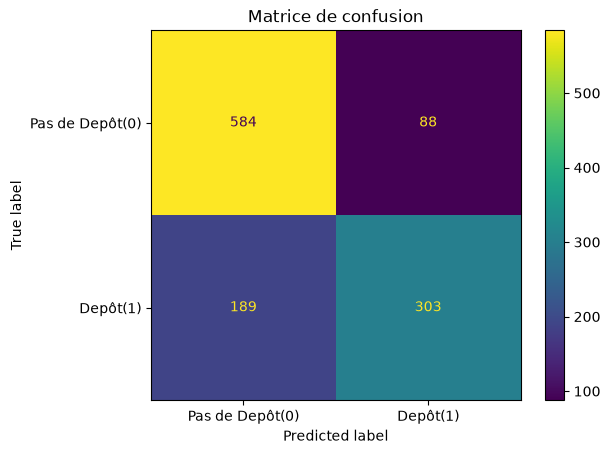

In [47]:
# Matrice confussion de lg
CM_funct(lg_model)

In [48]:
# Accuracy sur les données train
def evaluation_train(model):
  y_pred_train = model.predict(x_train)
  print(f'Accuracy sur les données train: {accuracy_score(y_train, y_pred_train): .3f}')

In [49]:
#
evaluation_train(lg_model)

Accuracy sur les données train:  0.764


### <font color = 'teal'>Support Vectors Machines (SVM)<font>

In [50]:
# Recherche des paramètres optimaux pour le svm
from sklearn.svm import SVC
# dictionnaire des params
param_ = {'C':np.logspace(-1,3,5), 'kernel':['linear','rbf', 'polynomial']}
# instantier le modèle svm
svm = SVC()
# instantier le modèle gridsearch
grid_ = GridSearchCV(svm, param_, cv =5)
# entrainer le modèle
grid_.fit(x_train, y_train)

KeyboardInterrupt: 

In [51]:
# afficher les paramètres optimaux




In [52]:
from sklearn.svm import SVC
# Entrainer svm en utilisant les paramètres optimaux, C = 1.0, kernel ='rbf'
svm_model = SVC(C = 1.0, kernel = 'rbf')
svm_model.fit(x_train, y_train)

,"C C: float, default=1.0Regularization parameter. The strength of the regularization isinversely proportional to C. Must be strictly positive. The penaltyis a squared l2 penalty. For an intuitive visualization of the effectsof scaling the regularization parameter C, see:ref:`sphx_glr_auto_examples_svm_plot_svm_scale_c.py`.",1.0
,"kernel kernel: {'linear', 'poly', 'rbf', 'sigmoid', 'precomputed'} or callable, default='rbf'Specifies the kernel type to be used in the algorithm. Ifnone is given, 'rbf' will be used. If a callable is given it is used topre-compute the kernel matrix from data matrices; that matrix should bean array of shape ``(n_samples, n_samples)``. For an intuitivevisualization of different kernel types see:ref:`sphx_glr_auto_examples_svm_plot_svm_kernels.py`.",'rbf'
,"degree degree: int, default=3Degree of the polynomial kernel function ('poly').Must be non-negative. Ignored by all other kernels.",3
,"gamma gamma: {'scale', 'auto'} or float, default='scale'Kernel coefficient for 'rbf', 'poly' and 'sigmoid'.- if ``gamma='scale'`` (default) is passed then it uses 1 / (n_features * X.var()) as value of gamma,- if 'auto', uses 1 / n_features- if float, must be non-negative... versionchanged:: 0.22 The default value of ``gamma`` changed from 'auto' to 'scale'.",'scale'
,"coef0 coef0: float, default=0.0Independent term in kernel function.It is only significant in 'poly' and 'sigmoid'.",0.0
,"shrinking shrinking: bool, default=TrueWhether to use the shrinking heuristic.See the :ref:`User Guide <shrinking_svm>`.",True
,"probability probability: bool, default=FalseWhether to enable probability estimates. This must be enabled priorto calling `fit`, will slow down that method as it internally uses5-fold cross-validation, and `predict_proba` may be inconsistent with`predict`. Read more in the :ref:`User Guide <scores_probabilities>`...deprecated:: 1.9 The `probability` parameter is deprecated and will be removed in 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`.",'deprecated'
,"tol tol: float, default=1e-3Tolerance for stopping criterion.",0.001
,"cache_size cache_size: float, default=200Specify the size of the kernel cache (in MB).",200
,"class_weight class_weight: dict or 'balanced', default=NoneSet the parameter C of class i to class_weight[i]*C forSVC. If not given, all classes are supposed to haveweight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.",None
,"verbose verbose: bool, default=FalseEnable verbose output. Note that this setting takes advantage of aper-process runtime setting in libsvm that, if enabled, may not workproperly in a multithreaded context.",False


##### <font color ='bisque'>Evaluation du SVM<font>

In [53]:
# Accuracy sur les données train
acc_svm, f1_svm = evaluation(svm_model)
print(f'Accuracy : {acc_svm: .3f} --- F1 : {f1_svm: .3f}')

Accuracy :  0.771 --- F1 :  0.701


In [55]:
# Accuracy sur les données train
evaluation_train(svm_model)

Accuracy sur les données train:  0.794


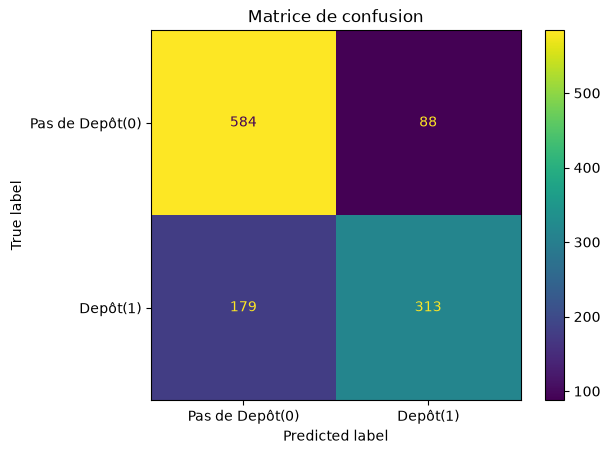

In [56]:
# y_pred_:  prédictions du modèle sur les données validation
CM_funct(svm_model)

### <font color = 'teal'>Decision Tree<font>

In [57]:
# Recherche des paramètres optimaux pour le Decision Tree
from sklearn.tree import DecisionTreeClassifier
# dictionnaire des params
param__ = {'criterion':['gini','entropy'],'max_depth':np.arange(3,15)}
# instantier le modèle Decision Tree
dt = DecisionTreeClassifier()
# instantier le modèle gridsearch
grid__ = GridSearchCV(dt, param__, cv = 5)
# entrainer le modèle
grid__.fit(x_train, y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",DecisionTreeClassifier()
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'criterion': ['gini', 'entropy'], 'max_depth': array([ 3, 4..., 12, 13, 14])}"
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",None
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"verbose verbose: int, default=0Controls the verbosity o

In [58]:
# afficher les paramètres optimaux
grid__.best_params_

{'criterion': 'gini', 'max_depth': np.int64(10)}

In [59]:
# Entrainer le modèle en utilisant les paramètres optimaux
dt_model = DecisionTreeClassifier(criterion = 'gini', max_depth = 10)
dt_model.fit(x_train, y_train)

,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",10
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split.",'best'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... note:: The search for a split does not stop until at least one valid partition of the node samples is found, even if it requires to effectively inspect more than ``max_features`` features.",None
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples 

##### <font color ='bisque'>Evaluation du Decision Tree<font>

In [60]:
# Accuracy sur les données train
acc_dt, f1_dt = evaluation(dt_model)
print(f'Accuracy : {acc_dt: .3f} --- F1 : {f1_dt: .3f}')

Accuracy :  0.827 --- F1 :  0.793


In [61]:
# Accuracy sur les données train
evaluation_train(dt_model)

Accuracy sur les données train:  0.876


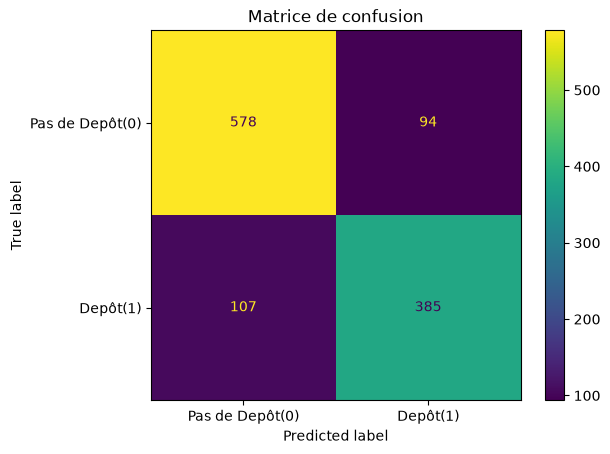

In [65]:
# y_pred__:  prédictions du modèle sur les données validation
CM_funct(dt_model)

In [63]:
# Diagramme en barre de comparaison des métrices
list_acc  =[acc_lg, acc_svm, acc_dt]
list_f1 = [f1_lg, f1_svm, f1_dt]
list_names = ['LG', 'SVM', 'DT']
for liste in [list_acc, list_f1]:
  fig = px.bar(y = list_names, x = liste, color = list_names, text_auto = True)
  fig.show()

### <font color ='bisque'>Tester le modèle le plus performant<font>

In [64]:
# echantillons de 10
x_test_10 = x_test[10:20]
y_test_10 = y_test[10:20]
class_names =['Pas Dépôt' , 'Dépôt']
y_pred_10 = dt_model.predict(x_test_10)
for i in range(10):
  print(f'Prédiction {str(i +1)} : {class_names[y_pred_10[i]]}   |  {class_names[y_test_10[i]]} ')

Prédiction 1 : Pas Dépôt   |  Pas Dépôt 
Prédiction 2 : Pas Dépôt   |  Pas Dépôt 
Prédiction 3 : Pas Dépôt   |  Pas Dépôt 
Prédiction 4 : Pas Dépôt   |  Pas Dépôt 
Prédiction 5 : Dépôt   |  Pas Dépôt 
Prédiction 6 : Dépôt   |  Dépôt 
Prédiction 7 : Dépôt   |  Dépôt 
Prédiction 8 : Pas Dépôt   |  Pas Dépôt 
Prédiction 9 : Pas Dépôt   |  Pas Dépôt 
Prédiction 10 : Pas Dépôt   |  Pas Dépôt 


In [66]:
# télécharger le modèle le plus performant
jb.dump(dt_model, 'models/dt_model.joblib')

['models/dt_model.joblib']

### <font color = 'gold'>Mettre l'application en ligne (Github + Streamlit)<font>

Les artefacts nécessaires à l'application (`models/dt_model.joblib`, `metadata/scaler.joblib`, `metadata/encoders.joblib`, `metadata/uniques.joblib`) ont déjà été sauvegardés plus haut dans le notebook.

Le déploiement se fait avec deux fichiers, à la racine du projet (comme dans le projet *Telecom Customer Segmentation*) :
- `app.py` : l'application Streamlit, qui s'appuie sur la classe générique `StreamlitModelDeployer` (`outils/deployment.py`) ;
- `requirements.txt` : la liste des dépendances à installer.

Pour lancer l'application (depuis un terminal, à la racine du projet) :

```bash
pip install -r requirements.txt
streamlit run app.py
```